<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_6/tugas_praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas Praktikum**

Jalankan code berikut pada Google Colab dan PyDroid3 (Android Python) Application di Smartphone Android. Bandingkan hasilnya dan tuliskan analisa anda, tuliskan juga spesifikasi smartphone yang anda gunakan :)



In [11]:
!pip install annoy hnswlib faiss-cpu

In [12]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

In [13]:
# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")


Exact NN done in 1.193 s
Annoy done in 0.558 s
HNSW done in 4.545 s
FAISS IVF done in 0.624 s

=== Ringkasan Waktu (detik) ===
Exact NN : 1.193
Annoy    : 0.558
HNSW     : 4.545
FAISS    : 0.624


#Hasil running kode pada smartphone


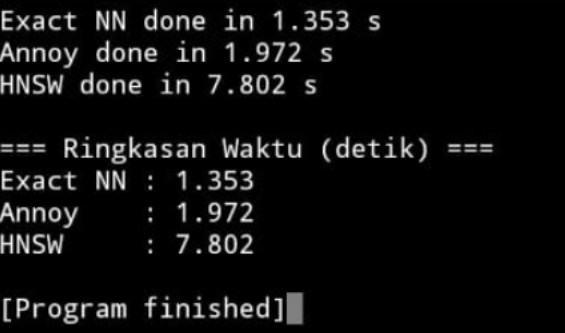

In [17]:
from IPython.display import Image
Image(filename='tugas_ml.png')



- Analisa perbandingan
    Google Colab memproses semua algoritma jauh lebih cepat daripada smartphone. Server cloud memiliki spesifikasi prosesor dan memori yang tinggi untuk komputasi berat. Smartphone menggunakan prosesor seluler yang mengutamakan efisiensi daya dan baterai.

    Pola performa algoritma berubah saat dijalankan pada smartphone. Di Google Colab, Annoy menjadi metode paling cepat. Pada smartphone, Exact NN justru menjadi yang tercepat. Pembuatan struktur indeks pohon dan graf pada Annoy dan HNSW membutuhkan alokasi memori yang rumit. Prosesor smartphone kesulitan memproses struktur data kompleks ini dengan cepat. Pencarian matematis langsung pada Exact NN menjadi lebih efisien untuk dataset berukuran 10.000 baris ini.

- Spesifikasi smartphone yang digunakan:
  1. Perangkat: Redmi Note 12 4G
  2. Kapasitas RAM: 6,0 GB   
  3. CPU atau Prosesor: Snapdragon 685 Octa-core Max 2.80GHz   
  4. Versi Android: 14